# 26장 · 디지털 이미지와 의료 영상 — 혈관은 끊기지 않았을까

이산위상 연구실 활용 편 · 글 안상선. 그대로 위에서부터 실행하면 돼요.

In [1]:
# 처음 한 번만: 필요한 패키지 설치 (구글 코랩이면 앞에 !를 붙여 그대로 실행)
# pip install numpy scipy matplotlib scikit-image networkx trimesh ripser

합성 혈관 영상에 **밝기 기준(임계값)**을 바꿔 가며 혈관을 골라내고, 조각(연결 성분) 수와 테두리(경계)를 셉니다. 실제 CT·MRI 분석에서 쓰는 순서와 같아요.

In [2]:
import numpy as np
from scipy import ndimage
from skimage.segmentation import find_boundaries

rng = np.random.default_rng(7)
H, W = 40, 64
I = 0.18 + 0.06 * rng.standard_normal((H, W))
segs = [(2,20,30,20,2.2,.92),(30,20,60,8,1.6,.72),(30,20,60,32,1.6,.72),(18,20,26,5,1.1,.55),(44,14,52,3,.9,.47),(44,26,55,38,.9,.47),(12,20,16,36,1.0,.52)]
yy, xx = np.mgrid[0:H, 0:W]
for x0, y0, x1, y1, w, v in segs:
    dx, dy = x1 - x0, y1 - y0
    u = np.clip(((xx - x0) * dx + (yy - y0) * dy) / (dx * dx + dy * dy), 0, 1)
    d = np.hypot(xx - x0 - u * dx, yy - y0 - u * dy)
    I = np.where(d <= w, np.maximum(I, v * (1 - .15 * u) + .05 * rng.standard_normal((H, W))), I)

for t in [0.30, 0.40, 0.45, 0.50, 0.60, 0.70]:
    mask = I >= t
    lab, n = ndimage.label(mask, structure=np.ones((3, 3)))
    sizes = np.bincount(lab.ravel())[1:]
    print(f"기준 {t:.2f}: 조각 {n:>3}개, 가장 큰 조각 {sizes.max() if n else 0:>4}자리")

기준 0.30: 조각  35개, 가장 큰 조각  471자리
기준 0.40: 조각   2개, 가장 큰 조각  442자리
기준 0.45: 조각   5개, 가장 큰 조각  418자리
기준 0.50: 조각   7개, 가장 큰 조각  367자리
기준 0.60: 조각   2개, 가장 큰 조각  321자리
기준 0.70: 조각  20개, 가장 큰 조각  167자리


기준이 낮으면 배경 잡음까지 혈관으로 잡혀 조각이 많아지고, 너무 높으면 가는 혈관이 끊깁니다. 작은 조각을 지우고(잡음 제거) 테두리를 뽑아 봅니다.

잡음 제거 뒤 조각: 1  테두리 자리: 230


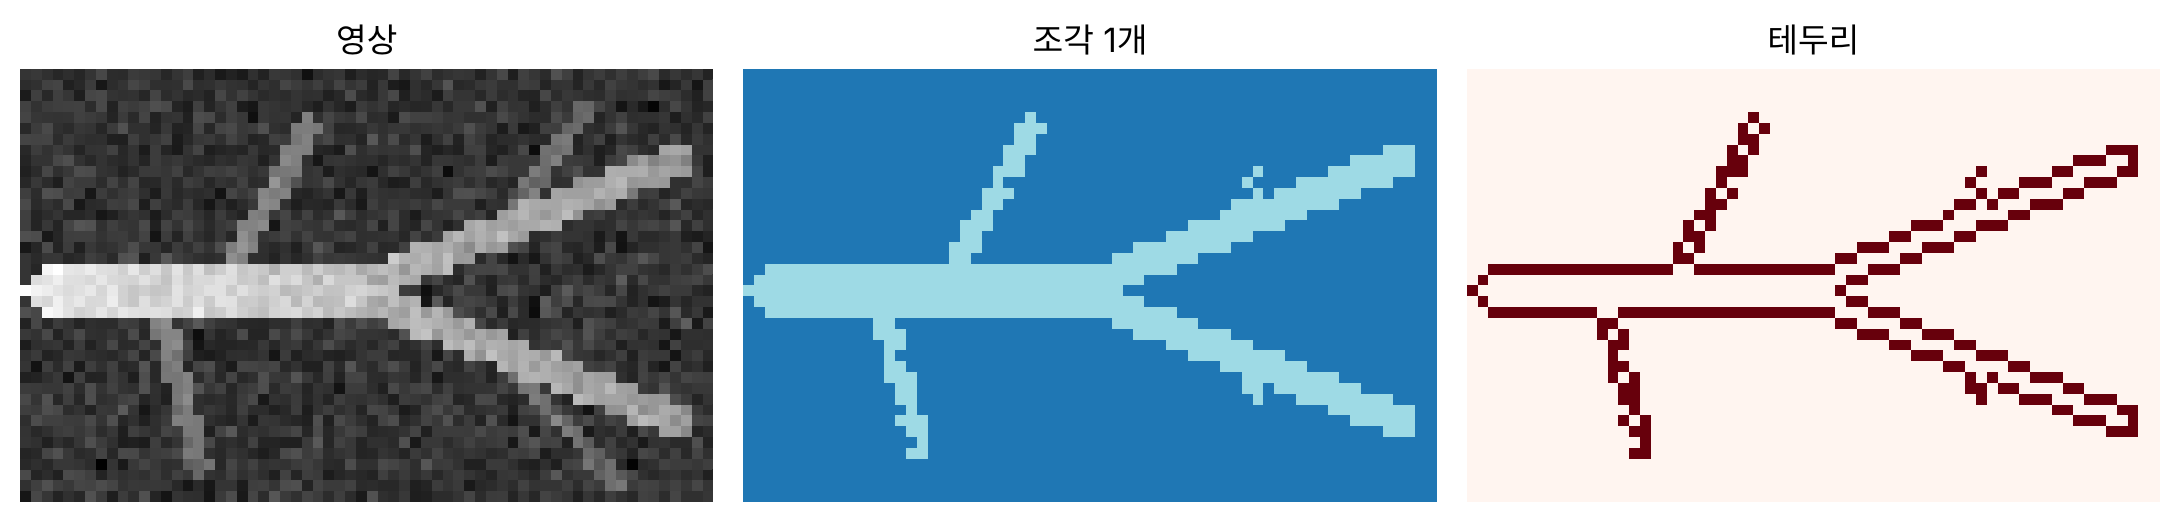

In [3]:
raw = I >= 0.45
lab0, n0 = ndimage.label(raw, structure=np.ones((3, 3)))
sizes = np.bincount(lab0.ravel()); sizes[0] = 0
mask = np.isin(lab0, np.where(sizes >= 6)[0])                 # 6자리보다 작은 조각 = 잡음으로 보고 지우기
lab, n = ndimage.label(mask, structure=np.ones((3, 3)))
edge = find_boundaries(mask, mode='inner')
print("잡음 제거 뒤 조각:", n, " 테두리 자리:", int(edge.sum()))
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))
ax[0].imshow(I, cmap='gray'); ax[0].set_title('영상')
ax[1].imshow(lab, cmap='tab20'); ax[1].set_title(f'조각 {n}개')
ax[2].imshow(edge, cmap='Reds'); ax[2].set_title('테두리')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()